In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El cliente de un proyecto de instalación pregunta por escrito si la obra estará terminada en la semana 23, porque ese día tiene comprometida la apertura. El cuadro de prelaciones y las tres estimaciones de duración de cada actividad (optimista, más probable y pesimista, en semanas) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b 
    ('A'     , '---'      , 2, 5, 8 ),
    ('B'     , '---'      , 1, 4, 7 ),
    ('C'     , '---'      , 3, 6, 9 ),
    ('D'     , 'B'        , 4, 7, 10),
    ('E'     , 'A,B,C'    , 4, 5, 12),
    ('F'     , 'E'        , 5, 6, 7 ),
    ('G'     , 'D'        , 2, 8, 8 ),
    ('H'     , 'F,G'      , 1, 1, 7 ),
    ('I'     , 'F'        , 1, 4, 7 ),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,2,5,8
B,---,1,4,7
C,---,3,6,9
D,B,4,7,10
E,"A,B,C",4,5,12
F,E,5,6,7
G,D,2,8,8
H,"F,G",1,1,7
I,F,1,4,7


> **De: Director comercial**
> Contéstale que «según la planificación, la ruta crítica termina en la semana 22», que es verdad y es antes de la 23. No le des probabilidades: si le hablas de un 60 % se pone nervioso y empieza a pedir penalizaciones.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C2 — Verdad a medias.** Comunicar un dato cierto omitiendo la parte que cambiaría su interpretación (dar la fecha de la ruta crítica sin la probabilidad de cumplirla). *(cf. Código Ético del PMI, 5.3.1.)*
- **C4 — Retención de información.** Callar un hecho conocido que la otra parte necesitaría para decidir (un riesgo, una holgura, una discrepancia). *(cf. Código Ético del PMI, 5.3.1 y 5.2.3.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la duración esperada del proyecto, la desviación típica del camino crítico y la probabilidad de terminar en la semana 23 o antes con la aproximación normal del PERT.  "
pregunta_2 = "2. (A) Repita el cálculo con una simulación Monte Carlo (20 000 réplicas, duraciones normales con la media y la desviación típica PERT de cada actividad) y obtenga además las semanas que se cumplirían con probabilidad 0,5 y 0,8. ¿Por qué la simulación da menos probabilidad que el PERT?  "
pregunta_3 = "3. (B) La frase «la ruta crítica termina en la semana 22» es cierta. ¿Cumple el criterio de referencia como respuesta a la pregunta del cliente? ¿Qué forma de engaño es y qué dato falta para que deje de serlo?  "
pregunta_4 = "4. (C) Redacte la respuesta al cliente y la nota interna al director comercial. Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la duración esperada del proyecto, la desviación típica del camino crítico y la probabilidad de terminar en la semana 23 o antes con la aproximación normal del PERT.  

2. (A) Repita el cálculo con una simulación Monte Carlo (20 000 réplicas, duraciones normales con la media y la desviación típica PERT de cada actividad) y obtenga además las semanas que se cumplirían con probabilidad 0,5 y 0,8. ¿Por qué la simulación da menos probabilidad que el PERT?  

3. (B) La frase «la ruta crítica termina en la semana 22» es cierta. ¿Cumple el criterio de referencia como respuesta a la pregunta del cliente? ¿Qué forma de engaño es y qué dato falta para que deje de serlo?  

4. (C) Redacte la respuesta al cliente y la nota interna al director comercial. Aplique la rúbrica de la lección.  

# Resolución

In [6]:
fecha_cliente = 23
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = (datos_proyecto['a'] + 4 * datos_proyecto['m'] + datos_proyecto['b']) / 6
datos_proyecto['standard_deviation'] = (datos_proyecto['b'] - datos_proyecto['a']) / 6
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion = float(proyecto.duration(datos_proyecto['duration']))
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
z = (fecha_cliente - duracion) / sigma
p_pert = float(norm.cdf(z))

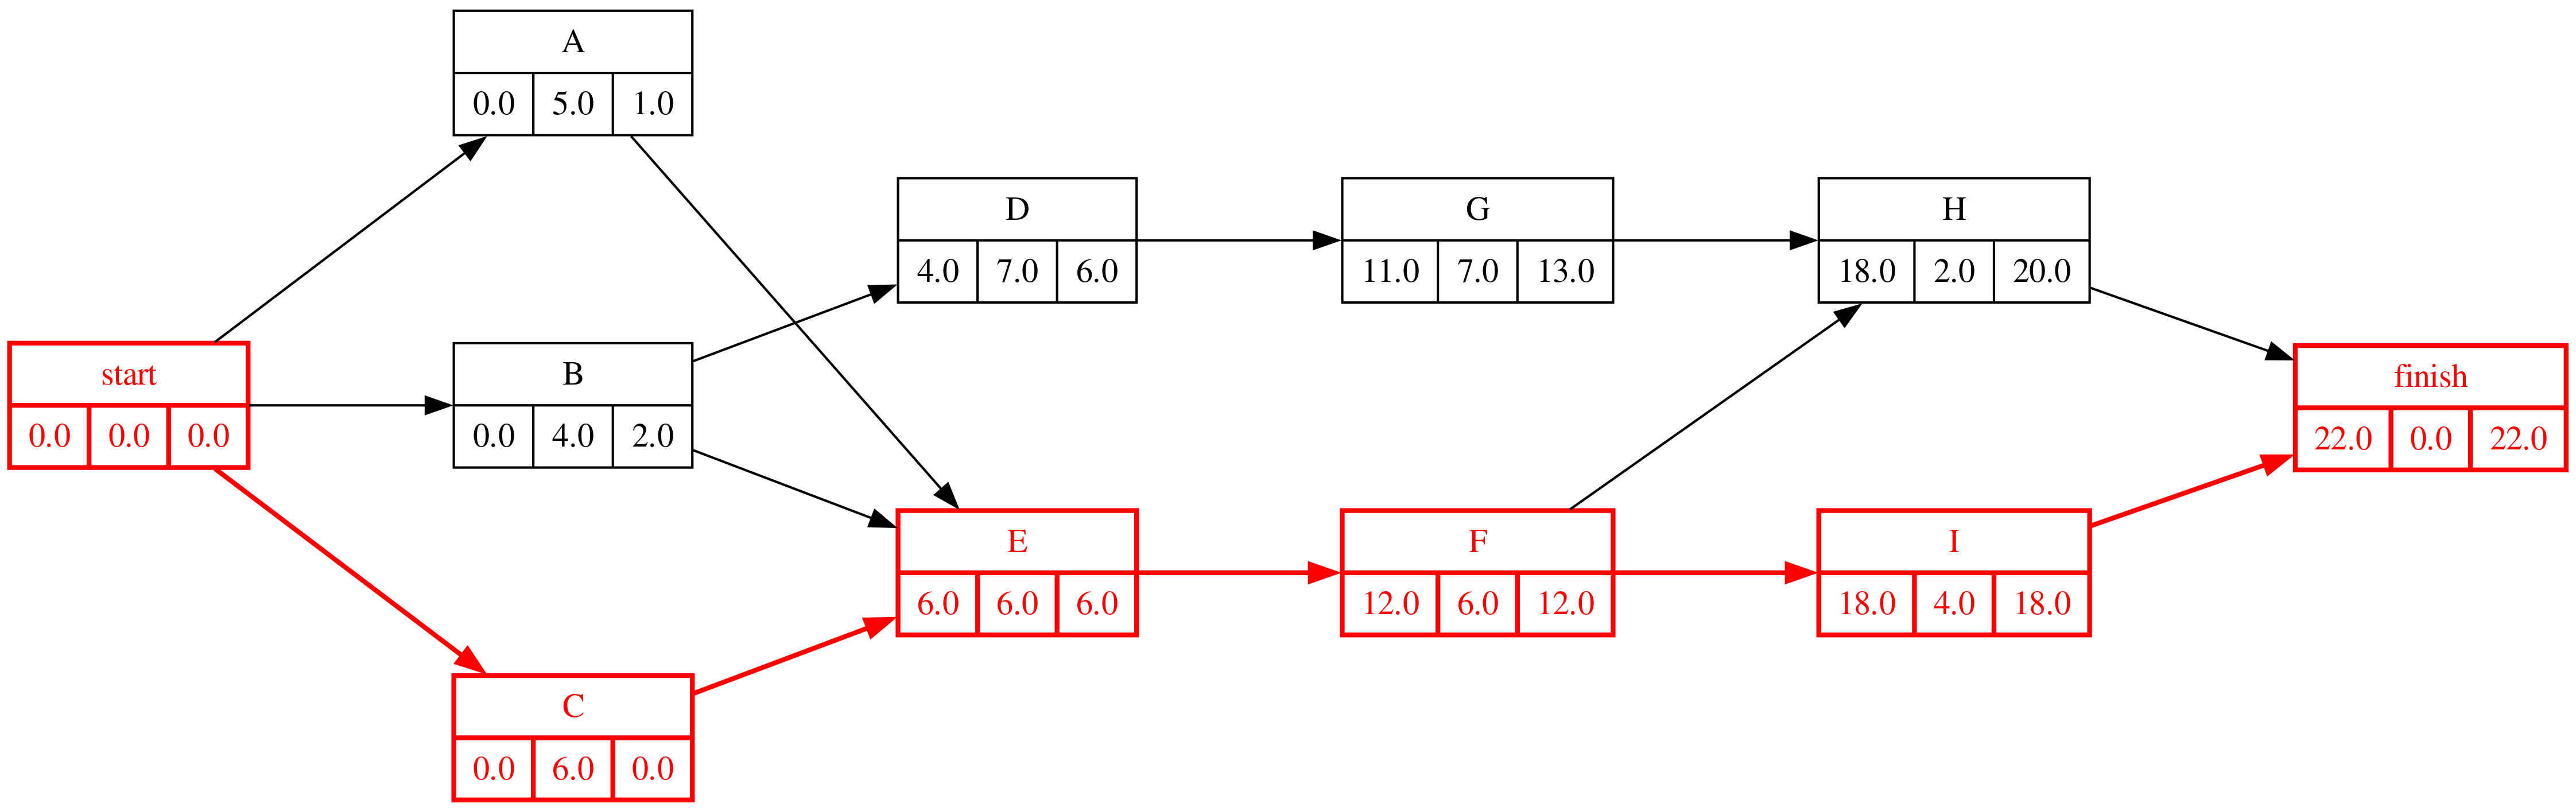

In [8]:
#| fig-cap: "Grafo Roy con las duraciones medias"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{D} = 0+4 = 4$ &nbsp; (B)
- $T_{E} = \max\{0+5,\ 0+4,\ 0+6\} = 6$ &nbsp; (A, B, C)
- $T_{F} = 6+6 = 12$ &nbsp; (E)
- $T_{G} = 4+7 = 11$ &nbsp; (D)
- $T_{H} = \max\{12+6,\ 11+7\} = 18$ &nbsp; (F, G)
- $T_{I} = 12+6 = 18$ &nbsp; (F)
- $T_{\mathrm{Fin}} = \max\{18+2,\ 18+4\} = 22$ &nbsp; (H, I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 22$
- $T_{I}^{*} = 22-4 = 18$ &nbsp; (Fin)
- $T_{H}^{*} = 22-2 = 20$ &nbsp; (Fin)
- $T_{G}^{*} = 20-7 = 13$ &nbsp; (H)
- $T_{F}^{*} = \min\{20-6,\ 18-6\} = 12$ &nbsp; (H, I)
- $T_{E}^{*} = 12-6 = 6$ &nbsp; (F)
- $T_{D}^{*} = 13-7 = 6$ &nbsp; (G)
- $T_{C}^{*} = 6-6 = 0$ &nbsp; (E)
- $T_{B}^{*} = \min\{6-4,\ 6-4\} = 2$ &nbsp; (D, E)
- $T_{A}^{*} = 6-5 = 1$ &nbsp; (E)
- $T_{\mathrm{Inicio}}^{*} = \min\{1-0,\ 2-0,\ 0-0\} = 0$ &nbsp; (A, B, C)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la duración esperada del proyecto, la desviación típica del camino crítico y la probabilidad de terminar en la semana 23 o antes con la aproximación normal del PERT.  

In [10]:
#| tbl-cap: "Media y varianza PERT de cada actividad"
#| label: tbl-estimaciones
detalle_estimaciones(datos_enunciado)

,D = (a + 4m + b)/6,σ² = ((b − a)/6)²
A,(2 + 4·5 + 8)/6 = 5.00,((8 − 2)/6)² = 1.000
B,(1 + 4·4 + 7)/6 = 4.00,((7 − 1)/6)² = 1.000
C,(3 + 4·6 + 9)/6 = 6.00,((9 − 3)/6)² = 1.000
D,(4 + 4·7 + 10)/6 = 7.00,((10 − 4)/6)² = 1.000
E,(4 + 4·5 + 12)/6 = 6.00,((12 − 4)/6)² = 1.778
F,(5 + 4·6 + 7)/6 = 6.00,((7 − 5)/6)² = 0.111
G,(2 + 4·8 + 8)/6 = 7.00,((8 − 2)/6)² = 1.000
H,(1 + 4·1 + 7)/6 = 2.00,((7 − 1)/6)² = 1.000
I,(1 + 4·4 + 7)/6 = 4.00,((7 − 1)/6)² = 1.000


In [11]:
#| tbl-cap: "Duración y varianza de cada ruta"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
display(detalle_rutas(R, datos_proyecto['duration'], 'duración', 2))
detalle_rutas(R, datos_proyecto['variance'], 'varianza', 3)

,actividades,duración = suma,duración
Route_1,A - E - F - H,A(5.00) + E(6.00) + F(6.00) + H(2.00) = 19.00,19.0
Route_2,A - E - F - I,A(5.00) + E(6.00) + F(6.00) + I(4.00) = 21.00,21.0
Route_3,B - D - G - H,B(4.00) + D(7.00) + G(7.00) + H(2.00) = 20.00,20.0
Route_4,B - E - F - H,B(4.00) + E(6.00) + F(6.00) + H(2.00) = 18.00,18.0
Route_5,B - E - F - I,B(4.00) + E(6.00) + F(6.00) + I(4.00) = 20.00,20.0
Route_6,C - E - F - H,C(6.00) + E(6.00) + F(6.00) + H(2.00) = 20.00,20.0
Route_7,C - E - F - I,C(6.00) + E(6.00) + F(6.00) + I(4.00) = 22.00,22.0


,actividades,varianza = suma,varianza
Route_1,A - E - F - H,A(1.000) + E(1.778) + F(0.111) + H(1.000) = 3.889,3.888889
Route_2,A - E - F - I,A(1.000) + E(1.778) + F(0.111) + I(1.000) = 3.889,3.888889
Route_3,B - D - G - H,B(1.000) + D(1.000) + G(1.000) + H(1.000) = 4.000,4.0
Route_4,B - E - F - H,B(1.000) + E(1.778) + F(0.111) + H(1.000) = 3.889,3.888889
Route_5,B - E - F - I,B(1.000) + E(1.778) + F(0.111) + I(1.000) = 3.889,3.888889
Route_6,C - E - F - H,C(1.000) + E(1.778) + F(0.111) + H(1.000) = 3.889,3.888889
Route_7,C - E - F - I,C(1.000) + E(1.778) + F(0.111) + I(1.000) = 3.889,3.888889


In [12]:
Markdown(f'''Duración esperada **{duracion:.2f}** semanas, σ del camino crítico **{sigma:.2f}**; z = ({fecha_cliente} − {duracion:.2f}) / {sigma:.2f} = {z:.2f} y **P(T ≤ {fecha_cliente}) = {p_pert:.2f}** con la aproximación normal del PERT.''')

Duración esperada **22.00** semanas, σ del camino crítico **1.97**; z = (23 − 22.00) / 1.97 = 0.51 y **P(T ≤ 23) = 0.69** con la aproximación normal del PERT.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Repita el cálculo con una simulación Monte Carlo (20 000 réplicas, duraciones normales con la media y la desviación típica PERT de cada actividad) y obtenga además las semanas que se cumplirían con probabilidad 0,5 y 0,8. ¿Por qué la simulación da menos probabilidad que el PERT?  

In [14]:
dists = {act: ('normal', fila['duration'], fila['standard_deviation']) for act, fila in datos_proyecto.iterrows()}
resultado = proyecto.monte_carlo(dists, n_samples=20000, seed=2024)
tau = np.asarray(resultado.tau_samples, dtype=float)
p_mc = float((tau <= fecha_cliente).mean())
p50, p80 = np.percentile(tau, 50), np.percentile(tau, 80)
display(resultado.summary().round(2))
Markdown(f'''Monte Carlo: **P(T ≤ {fecha_cliente}) = {p_mc:.2f}** (PERT: {p_pert:.2f}); mediana {p50:.1f} semanas; con probabilidad 0,8 se termina en **{p80:.1f}** semanas.''')

,mean,std,q05,q50,q95,min,max
τ,22.57,1.7,19.87,22.53,25.45,16.79,29.87


Monte Carlo: **P(T ≤ 23) = 0.61** (PERT: 0.69); mediana 22.5 semanas; con probabilidad 0,8 se termina en **24.0** semanas.

In [15]:
#| tbl-cap: "Índice de criticidad de las actividades"
#| label: tbl-criticidad
(resultado.sensitivity_mean * 100).round(1).to_frame('criticidad (%)').T

,E,F,I,C,H,B,D,G,A
criticidad (%),79.9,79.9,75.8,59.9,24.2,22.3,20.1,20.1,17.8


La simulación da menos probabilidad porque hay rutas casi críticas: el PERT sólo mira la ruta de mayor media, pero en muchas réplicas la más larga es otra (sesgo de fusión). Cuanto más parecidas son las rutas, más optimista es el PERT.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. (B) La frase «la ruta crítica termina en la semana 22» es cierta. ¿Cumple el criterio de referencia como respuesta a la pregunta del cliente? ¿Qué forma de engaño es y qué dato falta para que deje de serlo?  

**C2 (verdad a medias).** La frase es cierta y, aun así, no responde a lo que el cliente pregunta: él quiere saber si puede contar con la semana 23, y la respuesta honesta es «con una probabilidad de 61% (69% con el PERT)». Dar la duración media sin la dispersión lleva al cliente a concluir que la fecha está asegurada; el dato que falta es la **probabilidad** (o la semana que sí se puede comprometer con un 80 %: la 24). Omitirlo a sabiendas, como pide el director comercial, es además **C4**. No es C1: no se afirma nada falso.

In [17]:
preguntas_test = [
    ('«La ruta crítica termina en la semana 22» como respuesta a «¿estará en la semana 23?» es…', ['C2, verdad a medias', 'C1, afirmación falsa', 'una respuesta completa', 'C6, conflicto de interés'],
     'El dato es cierto pero omite la dispersión, que cambia la conclusión.'),
    ('El dato que convierte la respuesta en honesta es…', ['la probabilidad de cumplir la fecha', 'la suma de las duraciones', 'el número de rutas', 'el coste del proyecto'],
     'La media sin la probabilidad no dice si la fecha es alcanzable.'),
    ('La simulación Monte Carlo da menos probabilidad que el PERT porque…', ['hay rutas casi críticas (sesgo de fusión)', 'usa menos réplicas', 'las duraciones son enteras', 'el PERT es siempre pesimista'],
     'El PERT sólo mira la ruta de mayor media; en muchas réplicas la más larga es otra.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — verdad a medias')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — verdad a medias

::Ética 19 — verdad a medias P1::«La ruta crítica termina en la semana 22» como respuesta a «¿estará en la semana 23?» es… {=C2, verdad a medias ~C1, afirmación falsa ~una respuesta completa ~C6, conflicto de interés ####El dato es cierto pero omite la dispersión, que cambia la conclusión.}

::Ética 19 — verdad a medias P2::El dato que convierte la respuesta en honesta es… {~el coste del proyecto =la probabilidad de cumplir la fecha ~el número de rutas ~la suma de las duraciones ####La media sin la probabilidad no dice si la fecha es alcanzable.}

::Ética 19 — verdad a medias P3::La simulación Monte Carlo da menos probabilidad que el PERT porque… {~el PERT es siempre pesimista =hay rutas casi críticas (sesgo de fusión) ~usa menos réplicas ~las duraciones son enteras ####El PERT sólo mira la ruta de mayor media; en muchas réplicas la más larga es otra.}



## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. (C) Redacte la respuesta al cliente y la nota interna al director comercial. Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Respuesta al cliente (modelo): «La planificación da una duración esperada de 22 semanas; la probabilidad de terminar en la semana 23 es del 61%. La semana que podemos comprometer con un 80 % de confianza es la 24. Si la apertura exige la 23, podemos estudiar qué actividades acortar y a qué coste.» Nota interna: el cliente que descubre después que la fecha tenía un 39% de riesgo pedirá las penalizaciones igualmente, y con razón; la probabilidad no es una debilidad comercial sino la base para vender la reducción de plazo (lección 10).